# Select the maximum autoregressive lag

This mirrors the TEP maximum-lag notebook: fit one linear autoregression per child using its known causal parents, then select the shared maximum lag by multivariate BIC. Only healthy training runs are used for fitting. Lagged rows are constructed separately within each run to prevent time-series boundaries from leaking into one another. The SEM's largest true lag is two steps, but a wider search is evaluated rather than assuming that value.

In [1]:
from pathlib import Path
import sys


def _find_carl_project_root(start=Path.cwd()):
    start = start.resolve()
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").is_file() and (candidate / "data").is_dir():
            return candidate
    raise FileNotFoundError("Could not locate the project root from the notebook working directory.")


PROJECT_ROOT = _find_carl_project_root()
sys.path.insert(0, str(PROJECT_ROOT))
print(f"Project root: {PROJECT_ROOT}")

Project root: <repo>


In [2]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt


data_dir = PROJECT_ROOT / "data" / "interim" / "causalAIProcess"
graph_file = PROJECT_ROOT / "data" / "processed" / "causalAIProcess" / "causal_graph.csv"
models_dir = PROJECT_ROOT / "models" / "causalAIProcess" / "max_lag_selection"
models_dir.mkdir(parents=True, exist_ok=True)

training_file_name = "traces_scaled.parquet"
MAX_LAG_THRESHOLD = 19

In [3]:
df = pd.read_parquet(data_dir / training_file_name)
runs = pd.read_csv(PROJECT_ROOT / "data" / "processed" / "causalAIProcess" / "runs.csv")
causal_graph = pd.read_csv(graph_file)

faultfree_run_ids = runs.loc[
    runs["split"].eq("train") & runs["fault_type"].eq("healthy"), "run_id"
].unique()
df_faultfree = df.loc[df["run_id"].isin(faultfree_run_ids)].copy()
feature_names = [
    column
    for column in df_faultfree.columns
    if column not in ["run_id", "time_step", "time_seconds", "anomaly", "split"]
]
child_parents_pairs = {
    child: sorted(causal_graph.loc[causal_graph["target"] == child, "source"].unique())
    for child in feature_names
}
missing_children = set(feature_names) - set(child_parents_pairs)
if missing_children:
    raise ValueError(f"Causal graph has no parent entries for: {sorted(missing_children)}")
if df_faultfree.empty:
    raise ValueError("No healthy training runs are available for lag selection.")

model_features = {
    child: list(dict.fromkeys(parents + [child]))
    for child, parents in child_parents_pairs.items()
}
feature_indices = {feature: index for index, feature in enumerate(feature_names)}
n_faultfree_ts = len(faultfree_run_ids)
n_samples_per_ts = df_faultfree.groupby("run_id").size().min()
if df_faultfree.groupby("run_id").size().nunique() != 1:
    raise ValueError("Healthy training runs must have equal lengths for BIC comparison.")
if MAX_LAG_THRESHOLD >= n_samples_per_ts:
    raise ValueError("Maximum lag search must be shorter than each training run.")

print(f"Healthy training trajectories: {n_faultfree_ts}")
print(f"Samples per trajectory: {n_samples_per_ts}")
print(f"Variables: {len(feature_names)}; SEM edges: {len(causal_graph)}")
display(pd.DataFrame({"child": child_parents_pairs.keys(), "parents": child_parents_pairs.values()}))

Healthy training trajectories: 350
Samples per trajectory: 1000
Variables: 6; SEM edges: 14


,child,parents
0,feed_flow,[feed_flow]
1,feed_concentration,[feed_concentration]
2,coolant_flow,[coolant_flow]
3,reactor_concentration,"[feed_concentration, feed_flow, reactor_concen..."
4,reactor_temperature,"[coolant_flow, feed_flow, reactor_concentratio..."
5,product_quality,"[product_quality, reactor_concentration, react..."


,Max Lag,BIC
0,2,-3.088958e+06
1,3,-3.088793e+06
2,4,-3.088629e+06
3,5,-3.088461e+06
4,6,-3.088296e+06
5,7,-3.088128e+06
6,8,-3.087967e+06
7,9,-3.087802e+06
8,10,-3.087631e+06
9,11,-3.087465e+06


Best BIC score = -3088958.023 at max lag = 2


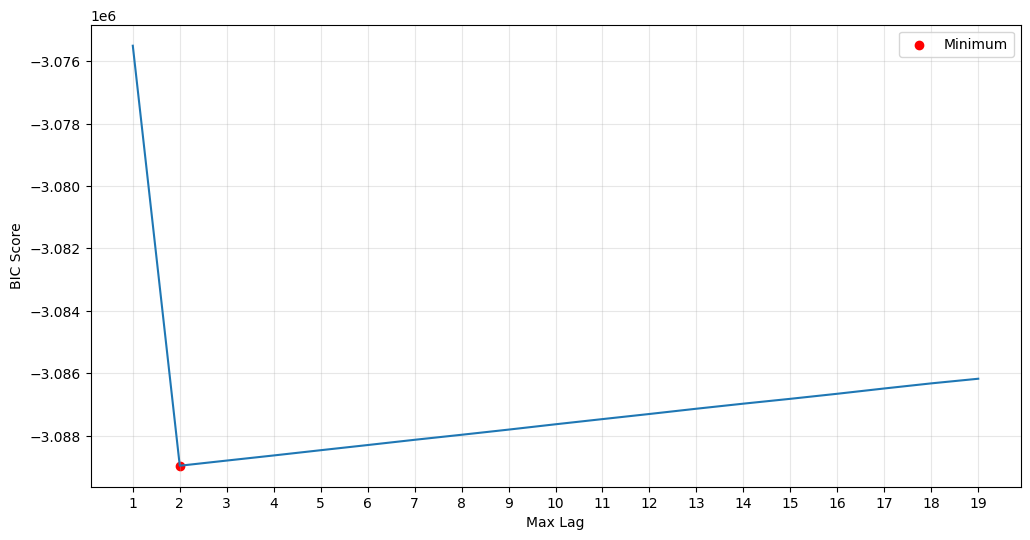

In [4]:
train_sequences = [
    trajectory[feature_names].to_numpy(dtype=float)
    for _, trajectory in df_faultfree.groupby("run_id", sort=False)
]


def create_lagged_arrays(sequence, parent_indices, child_idx, max_lag):
    n_rows = len(sequence) - max_lag
    lagged_features = np.concatenate(
        [
            sequence[max_lag - lag : len(sequence) - lag, parent_indices]
            for lag in range(1, max_lag + 1)
        ],
        axis=1,
    )
    x = np.ones((n_rows, lagged_features.shape[1] + 1))
    x[:, 1:] = lagged_features
    y = sequence[max_lag:, child_idx]
    return x, y


n_samples_for_bic = n_faultfree_ts * (n_samples_per_ts - MAX_LAG_THRESHOLD)
sample_cov_per_max_lag = {}
k_per_lag = {}
best_bic_by_lag = {}
best_beta_by_lag = {}

for max_lag in range(1, MAX_LAG_THRESHOLD + 1):
    beta_by_child = {}
    residual_matrix = np.empty((n_samples_for_bic, len(feature_names)))
    n_parameters = 0

    for child_idx, (child, parents) in enumerate(child_parents_pairs.items()):
        parent_indices = [feature_indices[name] for name in model_features[child]]
        gram = np.zeros((1 + len(parent_indices) * max_lag,) * 2)
        cross_product = np.zeros(gram.shape[0])
        for sequence in train_sequences:
            x_train, y_train = create_lagged_arrays(
                sequence, parent_indices, child_idx, max_lag
            )
            gram += x_train.T @ x_train
            cross_product += x_train.T @ y_train
        beta, *_ = np.linalg.lstsq(gram, cross_product, rcond=None)
        beta_by_child[child] = beta
        n_parameters += len(beta)

        padding = MAX_LAG_THRESHOLD - max_lag
        child_residuals = []
        for sequence in train_sequences:
            x_train, y_train = create_lagged_arrays(
                sequence, parent_indices, child_idx, max_lag
            )
            child_residuals.append((y_train - x_train @ beta)[padding:])
        residual_matrix[:, child_idx] = np.concatenate(child_residuals)

    sample_cov_per_max_lag[max_lag] = (residual_matrix.T @ residual_matrix) / n_samples_for_bic
    k_per_lag[max_lag] = n_parameters
    sign, log_determinant = np.linalg.slogdet(sample_cov_per_max_lag[max_lag])
    best_bic_by_lag[max_lag] = (
        n_samples_for_bic * log_determinant + n_parameters * np.log(n_samples_for_bic)
        if sign > 0
        else np.inf
    )
    best_beta_by_lag[max_lag] = beta_by_child

bic_scores = pd.DataFrame(
    [{"Max Lag": lag, "BIC": bic} for lag, bic in best_bic_by_lag.items()]
)
bic_scores_sorted = bic_scores.sort_values("BIC").reset_index(drop=True)
display(bic_scores_sorted)

best_bic_score = bic_scores_sorted.loc[0, "BIC"]
best_max_lag = int(bic_scores_sorted.loc[0, "Max Lag"])
print(f"Best BIC score = {best_bic_score:.3f} at max lag = {best_max_lag}")

bic_scores.to_csv(models_dir / "bic_scores.csv", index=False)
pd.DataFrame([{"best_max_lag": best_max_lag, "best_bic_score": best_bic_score}]).to_csv(
    models_dir / "selected_max_lag.csv", index=False
)
for child, beta in best_beta_by_lag[best_max_lag].items():
    np.save(models_dir / f"beta_child_{child}_lag_{best_max_lag}.npy", beta)
np.save(models_dir / "sample_covariance.npy", sample_cov_per_max_lag[best_max_lag])

plt.figure(figsize=(12, 6))
plt.plot(bic_scores["Max Lag"], bic_scores["BIC"])
plt.scatter(best_max_lag, best_bic_score, color="red", label="Minimum")
plt.xlabel("Max Lag")
plt.ylabel("BIC Score")
plt.xticks(range(1, MAX_LAG_THRESHOLD + 1))
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()